# Проектирование маршрутной сети

Сравнение методов поиска, изменение функции стоимости и построение маршрутных сетей готовой GAT-моделью.

In [ ]:
# Для работы в Google Colab раскомментируйте блок ниже.
# !git clone --depth 1 https://github.com/RuslanKozlyak/tndp_practice.git /content/tndp_practice
# %cd /content/tndp_practice
# %pip install -q .
#
# from google.colab import output
# output.enable_custom_widget_manager()

## Подготовка

### Параметры задачи и поиска

`alpha`: 0 — приоритет оператора, 1 — пассажира. `beta` — вес штрафа за нарушение связности.

In [ ]:
%matplotlib inline

import torch
import pandas as pd
from pathlib import Path
from dataclasses import replace
from IPython.display import display
from tndp import (
    ProblemConfig, GAConfig, PPOConfig, ExperimentConfig,
    compare_cost_functions, collect_data, dataset_table, train_or_load, compact_table,
    load_kemerovo, generate_routes, save_result, project_routes_to_roads, kemerovo_route_map,
    evaluate_rl, evaluate_lc, evaluate_evolution, evaluate_benchmark_pareto,
)
from tndp.visualization import (
    show_city, show_dataset_examples, show_training, show_method_routes,
    show_evolution, show_pareto, show_pareto_route_selector,
)

problem = ProblemConfig(
    n_nodes=20, 
    n_routes=10, 
    min_route_len=2, 
    max_route_len=12,
    alpha=0.3, 
    beta=5.0, 
    transfer_penalty=5.0,
)

ea_cfg = GAConfig(population_size=12,
                  generations=10,
                  mutation_steps=2,
                  mutation_probability=1.0,
                  shorten_probability=0.2)

table_metrics = ("cost", "ATT", "RTT", "d0", "d1", "d2", "un")

c:\Users\rkozl\Desktop\Лекция ИИ транспорт\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Параметры PPO используются при обучении модели.

In [ ]:
ppo_cfg = PPOConfig(
    total_updates=10,
    learning_rate=1.6e-3,
    batch_size=32,
    horizon=120, 
    minibatch_size=128, 
    n_epochs=1,
    gamma=1.0, 
    gae_lambda=0.95, 
    clip_range=0.2, 
    ent_coef=0.0,
    max_grad_norm=0.5, 
    variable_cost_weights=True,
    validation_every_updates=10, 
    validation_deterministic=False,
)

In [ ]:
config = ExperimentConfig(
    output_dir="artifacts/results/pretrained_eval",
    train=False,
    pretrained_weights="artifacts/weights/gat.pt",
    problem=problem, 
    ppo=ppo_cfg, 
    ea=ea_cfg, 
    metrics=table_metrics,
    lc_samples=2,
    pareto_weights = (0, 0.1, 0.2, 0.5, 1)
)
torch.set_num_threads(config.cpu_threads)

### Стоимость и показатели

Стоимость объединяет нормированные затраты пассажира, оператора и штраф за нарушения.
`state` содержит маршруты и матрицы города, `metrics` — показатели, `cfg` — параметры.

| Показатель | Значение |
|---|---|
| ATT, мин | Среднее время поездки по обслуженному спросу, включая пересадки |
| RTT, мин | Суммарное время маршрутов в обоих направлениях |
| d0, d1, d2, % | Доли спроса с нулём, одной и двумя пересадками на быстрейшем пути |
| un, % | Доля спроса с более чем двумя пересадками или без доступного пути |

#### Содержимое `state`

Состояние одной маршрутной сети. Времена заданы в минутах; массивы доступны только для чтения.
Матрицы имеют размер N × N, где N — число остановок; элемент `[i, j]` относится к поездке из i в j.

| Поле | Содержимое |
|---|---|
| `routes` | Маршруты как последовательности номеров остановок |
| `street_times` | Время по уличному ребру; `inf`, если ребра нет |
| `demand` | OD-спрос между остановками |
| `travel_times` | Быстрейшее время поездки по текущей сети со штрафами за пересадки; `inf`, если пути нет |
| `transfers` | Число пересадок на быстрейшем по времени пассажирском пути |
| `route_times` | Время каждого маршрута в одном направлении; порядок соответствует `routes` |
| `is_complete` | Признак завершения построения всей сети |


In [4]:
def cost_function(state, metrics, cfg):
    return (
        cfg.alpha * metrics["passenger_component"]
        + (1 - cfg.alpha) * metrics["operator_component"]
        + cfg.beta * metrics["constraint_component"]
    )

### Данные

Создание обучающей, валидационной и тестовой выборок с фиксированным seed.

In [5]:
datasets = collect_data(config)
display(dataset_table(datasets))

Генерация городов:   0%|          | 0/900 [00:00<?, ?city/s]

Генерация городов:   0%|          | 0/100 [00:00<?, ?city/s]

Генерация городов:   0%|          | 0/4 [00:00<?, ?city/s]

,Города
Обучение,900
Валидация,100
Проверка,4


Граф и OD-матрица первого тестового города; четыре примера обучающих графов.

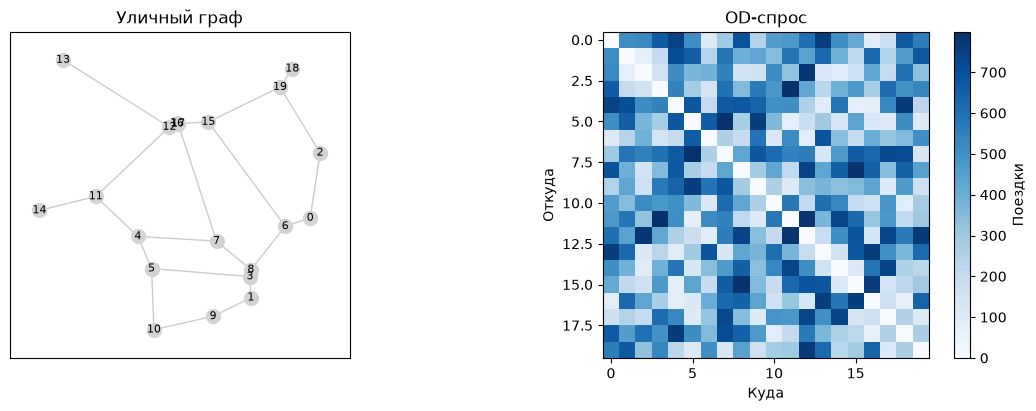

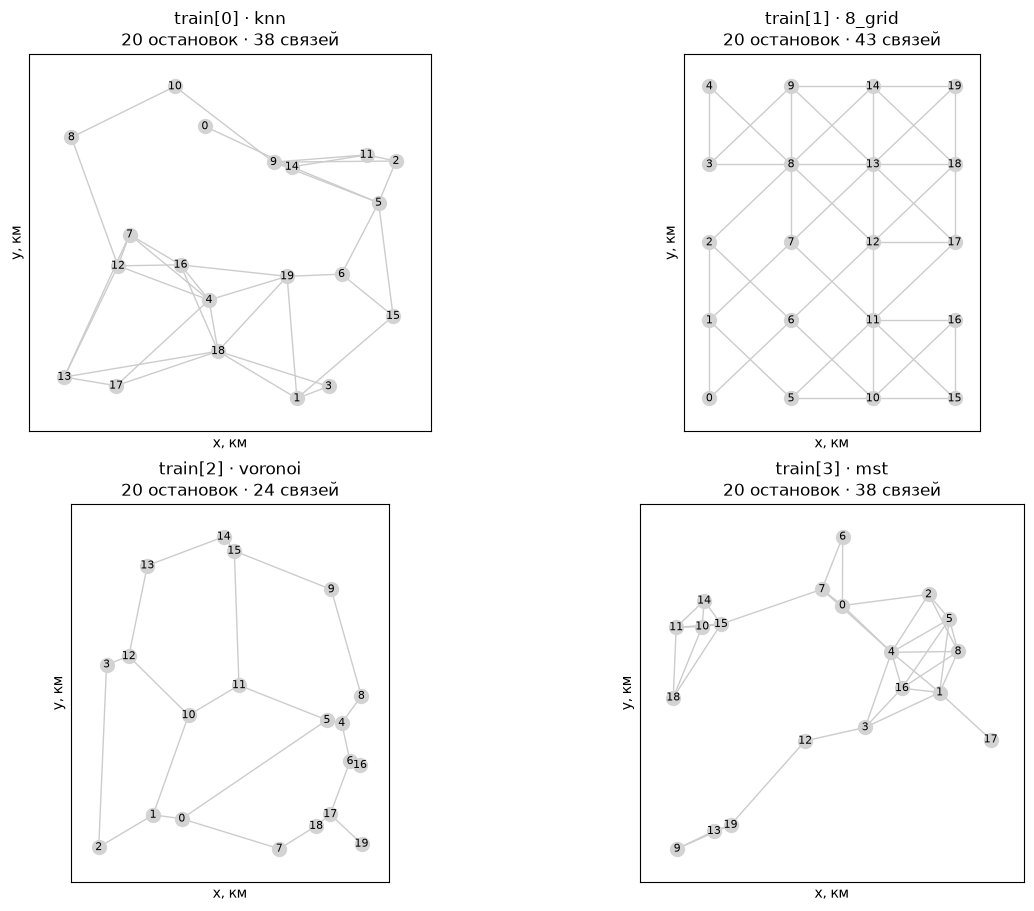

In [6]:
example_city = datasets["test"][0]
show_city(example_city);
show_dataset_examples(datasets["train"], config.output_dir, n_examples=4);

### Модель

Загрузка готовой политики. При обучении выводятся кривые стоимости на обучении и валидации.

In [7]:
training = train_or_load(config, datasets, cost_function)
show_training(training, config.output_dir);

# Пример обучения с нуля в отдельной папке результатов.
# training_config = replace(
#     config,
#     train=True,
#     pretrained_weights=None,
#     output_dir="artifacts/results/training_example",
# )
# training = train_or_load(training_config, datasets, cost_function)
# show_training(training, training_config.output_dir);


Сохранение данных:   0%|          | 0/4 [00:00<?, ?part/s]

## 1. Сравнение методов при фиксированном α

Методы используют одинаковые тестовые города и функцию стоимости.
Таблица содержит средние показатели, карты — сети первого тестового города.

| Метод | Построение сети |
|---|---|
| RL | Жадное построение готовой политикой |
| LC | Лучшая из `config.lc_samples` сетей: жадной и случайных |
| EA | Улучшение сети LC обычными мутациями |
| NEA | Улучшение той же сети LC с заменой маршрута политикой |

### 1.1 Reinforcement learning

In [8]:
rl = evaluate_rl(datasets["test"], config, training)
lc = evaluate_lc(datasets["test"], config, training, rl)

RL:   0%|          | 0/4 [00:00<?, ?city/s]

Построение сети:   0%|          | 0/10 [00:00<?, ?route/s]

Построение сети:   0%|          | 0/10 [00:00<?, ?route/s]

Построение сети:   0%|          | 0/10 [00:00<?, ?route/s]

Построение сети:   0%|          | 0/10 [00:00<?, ?route/s]

LC2:   0%|          | 0/4 [00:00<?, ?city/s]

LC2:   0%|          | 0/2 [00:00<?, ?sample/s]

LC2:   0%|          | 0/2 [00:00<?, ?sample/s]

LC2:   0%|          | 0/2 [00:00<?, ?sample/s]

LC2:   0%|          | 0/2 [00:00<?, ?sample/s]

### 1.2 Evolutionary algorithms

#### Как отличаются мутации

- **Добавление (EA и NEA):** соседняя остановка добавляется к началу или концу маршрута.
- **Удаление (EA и NEA):** убирается первая или последняя остановка.
- **Замена EA:** маршрут заменяется кратчайшим путём от одной концевой остановки к новой.
- **Замена NEA:** политика строит новый маршрут с учётом оставшейся сети.

Изменение сохраняется при уменьшении стоимости C.

EA / NEA:   0%|          | 0/4 [00:00<?, ?city/s]

EA:   0%|          | 0/10 [00:00<?, ?gen/s]

NEA:   0%|          | 0/10 [00:00<?, ?gen/s]

EA:   0%|          | 0/10 [00:00<?, ?gen/s]

NEA:   0%|          | 0/10 [00:00<?, ?gen/s]

EA:   0%|          | 0/10 [00:00<?, ?gen/s]

NEA:   0%|          | 0/10 [00:00<?, ?gen/s]

EA:   0%|          | 0/10 [00:00<?, ?gen/s]

NEA:   0%|          | 0/10 [00:00<?, ?gen/s]

,C,ATT,RTT,d0,d1,d2,un
Метод,,,,,,,
RL,0.591,27.117,300.979,44.083,40.699,13.396,1.823
LC2,0.590,28.229,294.513,42.444,39.395,14.803,3.358
EA (LC2),0.576,28.561,279.944,39.657,41.528,16.530,2.285
NEA (LC2),0.532,29.770,239.722,36.416,38.437,19.815,5.333


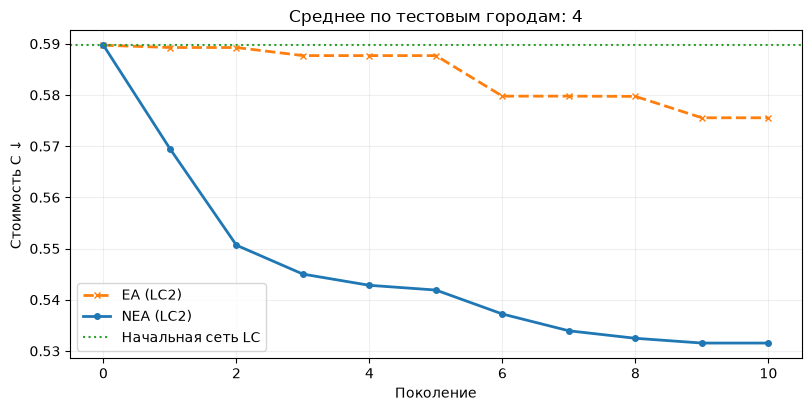

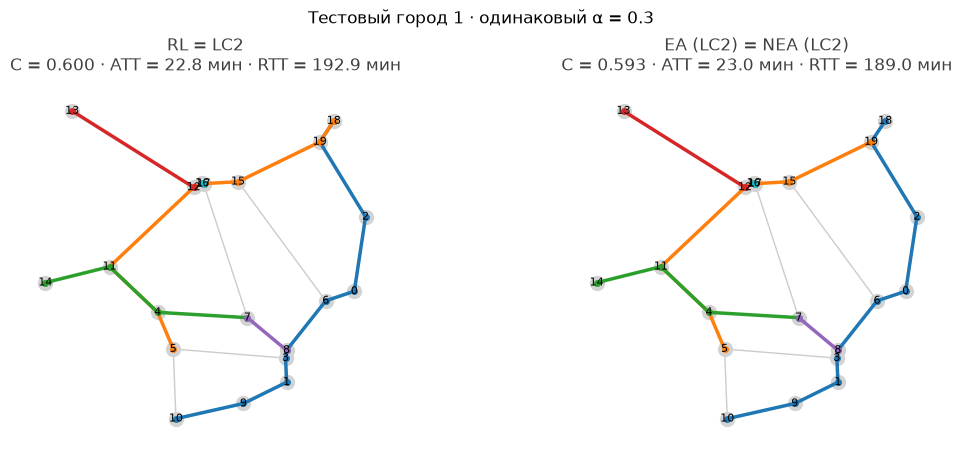

In [9]:
evolution = evaluate_evolution(datasets["test"], config, training, lc)
method_comparison = {
    "scores": pd.concat([rl["scores"], lc["scores"], evolution["scores"]], ignore_index=True),
    "results": {**rl["results"], **lc["results"], **evolution["results"]},
    "metrics": config.metrics,
}

display(compact_table(method_comparison))
show_evolution(evolution, config.output_dir, initial=lc);
show_method_routes(method_comparison, example_city, config.output_dir, city_index=0);

## 2. Изменение функции стоимости

Сравнение трёх функций стоимости методом NEA на одном валидационном городе.

| Функция | Дополнительный штраф |
|---|---|
| Базовая | — |
| Короткие маршруты | Суммарное превышение 30 минут у отдельных маршрутов |
| Прямые поездки | Доля спроса без прямого сообщения: `1 - d0 / 100` |

Оба дополнительных показателя рассчитываются для каждой итоговой сети.

In [ ]:
def long_routes_constraint(state, metrics, cfg):
    excess = sum(max(minutes - 30.0, 0.0) for minutes in state.route_times)
    return excess / (30.0 * cfg.n_routes)


def short_routes_cost(state, metrics, cfg, long_routes_weight=0.5):
    long_routes = long_routes_constraint(state, metrics, cfg)
    metrics["long_routes_constraint"] = long_routes
    return cost_function(state, metrics, cfg) + cfg.beta * long_routes_weight * long_routes


def indirect_demand_constraint(state, metrics, cfg):
    return 1.0 - metrics["d0"] / 100.0


def direct_trips_cost(state, metrics, cfg, indirect_demand_weight=0.5):
    indirect_demand = indirect_demand_constraint(state, metrics, cfg)
    metrics["indirect_demand_constraint"] = indirect_demand
    return cost_function(state, metrics, cfg) + cfg.beta * indirect_demand_weight * indirect_demand


extra_metrics = [long_routes_constraint, indirect_demand_constraint]
cost_functions = {
    "Базовая": cost_function,
    "Штраф за маршруты дольше 30 минут": short_routes_cost,
    "Штраф за поездки без прямого маршрута": direct_trips_cost,
}

Инициализация NEA: LC2:   0%|          | 0/1 [00:00<?, ?city/s]

LC2:   0%|          | 0/2 [00:00<?, ?sample/s]

NEA:   0%|          | 0/1 [00:00<?, ?city/s]

NEA:   0%|          | 0/10 [00:00<?, ?gen/s]

Инициализация NEA: LC2:   0%|          | 0/1 [00:00<?, ?city/s]

...

Инициализация NEA: LC2:   0%|          | 0/1 [00:00<?, ?city/s]

LC2:   0%|          | 0/2 [00:00<?, ?sample/s]

NEA:   0%|          | 0/1 [00:00<?, ?city/s]

NEA:   0%|          | 0/10 [00:00<?, ?gen/s]

,,C,ATT,RTT,d0,d1,d2,un,long_routes_constraint,indirect_demand_constraint
Функция,Метод,,,,,,,,,
Базовая,NEA (LC2),0.539,27.321,254.627,32.340,43.112,21.692,2.856,0.070,0.677
Штраф за маршруты дольше 30 минут,NEA (LC2),0.689,31.819,233.450,26.688,32.331,21.370,19.611,0.061,0.733
Штраф за поездки без прямого маршрута,NEA (LC2),2.059,24.972,344.963,43.881,47.630,8.325,0.164,0.105,0.561


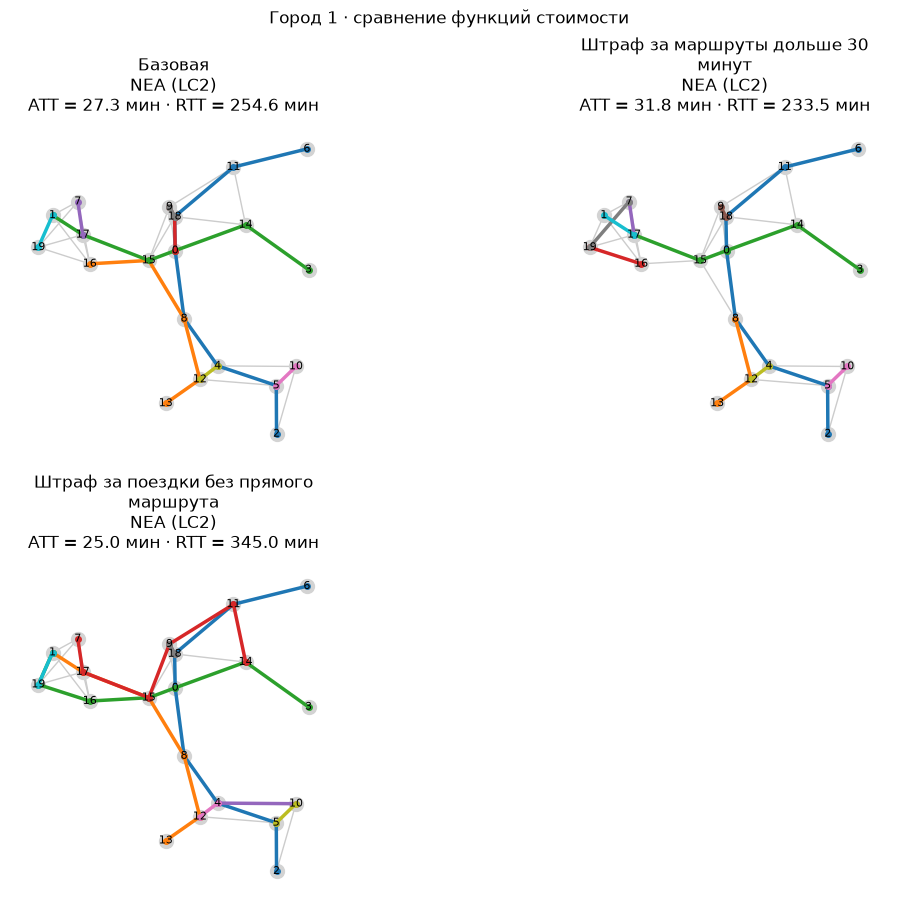

In [ ]:
cost_comparison = compare_cost_functions(
    datasets["validation"][:1], config, training, cost_functions,
    methods=("nea",),
    metric_functions=extra_metrics,
)

## 3. Парето: Mumford 0

Перебор α из `config.pareto_weights`: 30 остановок, 12 маршрутов, длины от 2 до 15 остановок.
`pareto_methods` задаёт методы: `"rl"`, `"lc"`, `"ea"`, `"nea"`; по умолчанию — NEA.
EA и NEA используют общий старт LC.

In [12]:
pareto_methods = ("nea",)
# Например: ("ea", "nea") или ("rl", "lc", "ea", "nea").

Парето:   0%|          | 0/5 [00:00<?, ?run/s]

LC2:   0%|          | 0/2 [00:00<?, ?sample/s]

NEA:   0%|          | 0/10 [00:00<?, ?gen/s]

LC2:   0%|          | 0/2 [00:00<?, ?sample/s]

NEA:   0%|          | 0/10 [00:00<?, ?gen/s]

...

LC2:   0%|          | 0/2 [00:00<?, ?sample/s]

NEA:   0%|          | 0/10 [00:00<?, ?gen/s]

LC2:   0%|          | 0/2 [00:00<?, ?sample/s]

NEA:   0%|          | 0/10 [00:00<?, ?gen/s]

,method,alpha,cost,ATT,RTT,d0,d1,d2,un,feasible,pareto
0,NEA (LC2),0.0,0.795,34.356,248.0,14.487,25.760,26.917,32.836,True,False
1,NEA (LC2),0.1,0.807,26.844,244.0,16.060,31.396,34.121,18.423,True,True
2,NEA (LC2),0.2,0.831,28.734,238.0,16.729,30.945,31.199,21.128,True,True
3,NEA (LC2),0.5,0.882,22.175,284.0,17.951,47.375,28.148,6.526,True,True
4,NEA (LC2),1.0,0.692,18.003,500.0,37.079,57.271,5.649,0.000,True,True


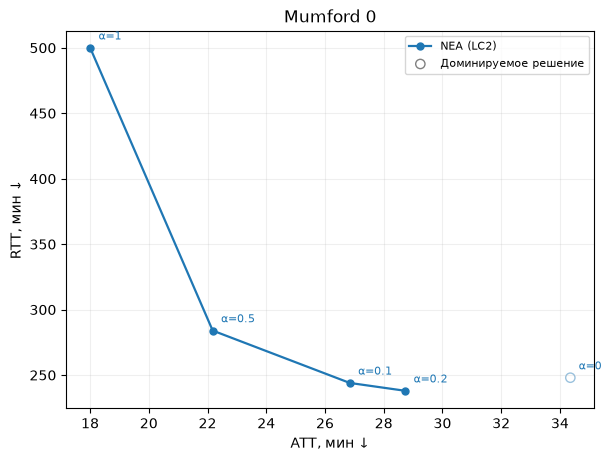

In [13]:
pareto_points = evaluate_benchmark_pareto(config, training, methods=pareto_methods)
pareto_output = Path(config.output_dir) / "mumford0"

display(pareto_points[["method", "alpha", *config.metrics, "feasible", "pareto"]].round(3))
show_pareto(pareto_points, pareto_output, title="Mumford 0");

Линии — фронты Парето каждого метода, пустые точки — доминируемые решения.

### Сохранённые маршруты

Показ сохранённой сети по методу и α.

In [ ]:
pareto_route_viewer = show_pareto_route_selector(config);

## 4. Кемерово

Жадное построение 20 маршрутов готовой моделью на графе Кемерова.

In [ ]:
kemerovo = load_kemerovo()

kemerovo_problem = replace(config.problem, n_nodes=kemerovo.city.n_nodes,
                           n_routes=20, min_route_len=2, max_route_len=30)

kemerovo_output = Path(config.output_dir) / "kemerovo"

kemerovo_result = generate_routes(
    kemerovo.city, kemerovo_problem, method="rl", policy=training["policies"]["gat"],
    deterministic=True, cost_function=training["cost_function"],
)
save_result(kemerovo_result, kemerovo_output)

Построение сети:   0%|          | 0/20 [00:00<?, ?route/s]

### Маршруты на карте

Слева — упрощённый граф, справа — те же маршруты по дорогам.
Масштаб, перемещение и слои маршрутов синхронизированы.

In [16]:
kemerovo_road_routes = project_routes_to_roads(
    kemerovo, kemerovo_result["routes"], kemerovo_output,
)
kemerovo_map = kemerovo_route_map(
    kemerovo, kemerovo_result["routes"], kemerovo_output, projected=kemerovo_road_routes,
)
display(kemerovo_map)